# Logistic Regression Model

## Modules

In [87]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Data Preprocessing and Setup

In [88]:
train_df = pd.read_csv("crime_train.csv")
test_df = pd.read_csv("crime_test.csv")

def zscore_normalisation(x, train_mu=None, train_sigma=None):
    # the point of none is when calculating the test set, we want to use the mean and std of the training set to normalise the test set
    if train_mu is None:
        train_mu = np.mean(x, axis=0)
    if train_sigma is None:
        train_sigma = np.std(x, axis=0)
        train_sigma[train_sigma == 0] = 1
    return (x - train_mu) / train_sigma, train_mu, train_sigma

train_df = train_df[(train_df['age'] % 1 == 0) & (train_df['police_department'] % 1 == 0)]
train_df = train_df.reset_index(drop=True)
test_df = test_df[(test_df['age'] % 1 == 0) & (test_df['police_department'] % 1 == 0)]
test_df = test_df.reset_index(drop=True)


weak = ["case_filed", "Unnamed: 0", "Num"]
train_df = train_df.drop(columns=weak)
test_df = test_df.drop(columns=weak)

train_df['weapon'] = train_df['weapon'].fillna('Unknown')
test_df['weapon'] = test_df['weapon'].fillna('Unknown')

train_df["closed"] = train_df["closed"].map({"Yes": 1, "No": 0})
test_df["closed"] = test_df["closed"].map({"Yes": 1, "No": 0})

cols_encode = ["city", "crime_description", "sex", "weapon", "domain"]
train_df = pd.get_dummies(train_df, columns=cols_encode, drop_first=True, dtype=int)
test_df = pd.get_dummies(test_df, columns=cols_encode, drop_first=True, dtype=int)

# Align test set with train set to ensure identical column structures
train_df, test_df = train_df.align(test_df, join='left', axis=1, fill_value=0)


# Normalize 
cols_scale = ['area', 'age', 'police_department']
x_train_cont = train_df[cols_scale].to_numpy(dtype=float)
x_test_cont = test_df[cols_scale].to_numpy(dtype=float)

x_train_cont, train_mu, train_sigma = zscore_normalisation(x_train_cont)
x_test_cont, _, _ = zscore_normalisation(x_test_cont, train_mu, train_sigma)

train_df[cols_scale] = x_train_cont
test_df[cols_scale] = x_test_cont


target = "closed"
features = train_df.columns.tolist()
features.remove(target)

x = train_df[features].to_numpy(dtype=float)
y = train_df[target].to_numpy(dtype=float)
x_test = test_df[features].to_numpy(dtype=float)
y_test = test_df[target].to_numpy(dtype=float)


## Functions

In [89]:
def compute_loss(x, y, w, b):
    m = x.shape[0]
    z = np.dot(x, w) + b
    z = np.clip(z, -500, 500)
    hyp = 1 / (1 + np.exp(-z))
    
    epsilon = 1e-15
    hyp = np.clip(hyp, epsilon, 1 - epsilon)
    
    loss = np.sum(y * np.log(hyp) + (1 - y) * np.log(1 - hyp)) / m
    return loss


def compute_derivative(x, y, w, b):
    m = x.shape[0]
    z = np.dot(x, w) + b
    z = np.clip(z, -500, 500)
    hyp = 1/(1+np.exp(-z))
    dhyp_dw = np.dot(x.T, (y-hyp)) / m
    dhyp_db = np.sum(y-hyp) / m
    return dhyp_dw, dhyp_db



def gradient_descent(x, y, w_in, b_in, alpha, num_iters):
    cost_history = []
    w = w_in.copy()
    b = b_in
    
    for i in range(num_iters):
        dj_dw, dj_db = compute_derivative(x, y, w, b)   

        # Update Parameters 
        w = w + alpha * dj_dw               
        b = b + alpha * dj_db               
      
        loss= compute_loss(x, y, w, b)
        cost_history.append(loss)

        if i% 100 == 0:
            print(f"Iteration {i}: Cost {loss} ")
        
    return w, b, cost_history 

## Model

In [90]:
w = np.zeros(x.shape[1])
b = 0.0

w, b, cost_history = gradient_ascent(x, y, w, b, 0.01, 10000)

print("Final cost:", cost_history[-1])

Iteration 0: Cost -0.6931466794982712 
Iteration 100: Cost -0.6931005111572051 
Iteration 200: Cost -0.6930604224083575 
Iteration 300: Cost -0.6930247228248678 
Iteration 400: Cost -0.6929924018149751 
Iteration 500: Cost -0.6929628041056892 
Iteration 600: Cost -0.6929354742243178 
Iteration 700: Cost -0.6929100775737758 
Iteration 800: Cost -0.6928863577424542 
Iteration 900: Cost -0.6928641118554881 
Iteration 1000: Cost -0.6928431754338429 
Iteration 1100: Cost -0.6928234125660443 
Iteration 1200: Cost -0.69280470922065 
Iteration 1300: Cost -0.6927869685136855 
Iteration 1400: Cost -0.6927701072496364 
Iteration 1500: Cost -0.6927540533255067 
Iteration 1600: Cost -0.6927387437399823 
Iteration 1700: Cost -0.692724123039378 
Iteration 1800: Cost -0.6927101420867765 
Iteration 1900: Cost -0.6926967570753816 
Iteration 2000: Cost -0.69268392872966 
Iteration 2100: Cost -0.692671621653002 
Iteration 2200: Cost -0.6926598037910743 
Iteration 2300: Cost -0.6926484459874288 
Iteration 

## Graph

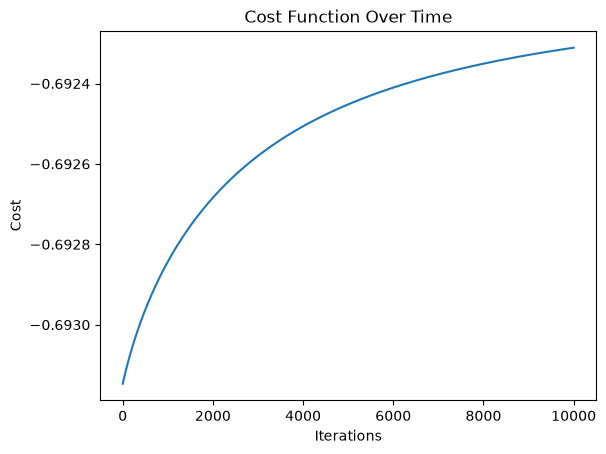

Final parameters - Bias: -0.01454870561651679 Weights: [-0.00508178  0.0006176  -0.00668254 -0.02777301 -0.03784987 -0.00879311
  0.01487152 -0.00178301 -0.00042819  0.02975683  0.02219177 -0.03147538
  0.02429613 -0.02381912  0.02817437  0.00640673  0.05947387  0.04957543
  0.01523214 -0.06541984  0.01749814  0.01365432 -0.0165234  -0.03672207
  0.0131286  -0.03304656  0.0047108  -0.0019836  -0.02606918 -0.00013739
 -0.01301857  0.00052801 -0.02116091 -0.0408712  -0.00604566  0.0557963
 -0.03284492 -0.025861   -0.00608896  0.08970251  0.03122365  0.05741917
  0.0419485  -0.0139252   0.0109648  -0.04200177 -0.02548709 -0.02255486
  0.01630526  0.00234934  0.01023697  0.00114558  0.02465193 -0.07165809
 -0.03565995 -0.01982316  0.04122653  0.03183112  0.03036748  0.01292505
  0.01630526  0.05649159]
Gradient size: 0.001274212599883189
Bias gradient: -0.00017030207708250756
False
False


In [91]:
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Function Over Time")
plt.show()

dj_dw, dj_db = compute_derivative(x, y, w, b)

print("Final parameters - Bias:", b, "Weights:", w)
print("Gradient size:", np.linalg.norm(dj_dw))
print("Bias gradient:", dj_db)
print(np.isclose(np.linalg.norm(dj_dw), 0, atol=1e-5))
print(np.isclose(dj_db, 0, atol=1e-5))



## Test

In [92]:
z_test = np.dot(x_test, w) + b
z_test = np.clip(z_test, -500, 500)

hyp_test = 1 / (1 + np.exp(-z_test))

predictions = (hyp_test >= 0.5).astype(int)

In [93]:
accuracy = np.mean(predictions == y_test)

# Confusion matrix counts
tp = np.sum((predictions == 1) & (y_test == 1))
tn = np.sum((predictions == 0) & (y_test == 0))
fp = np.sum((predictions == 1) & (y_test == 0))
fn = np.sum((predictions == 0) & (y_test == 1))

# Precision, recall, F1
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

eps = 1e-15
p = np.clip(hyp_test, eps, 1 - eps)
log_loss = -np.mean(y_test * np.log(p) + (1 - y_test) * np.log(1 - p))

base = np.clip(np.mean(y), eps, 1 - eps)
ll_model = np.sum(y_test * np.log(p) + (1 - y_test) * np.log(1 - p))
ll_null = np.sum(y_test * np.log(base) + (1 - y_test) * np.log(1 - base))
mcfadden_r2 = 1 - ll_model / ll_null

print(f"Confusion: TP={tp} TN={tn} FP={fp} FN={fn}")
print(f"Accuracy:  {accuracy}")
print(f"Precision: {precision}")
print(f"Recall:    {recall}")
print(f"F1:        {f1}")
print(f"Log loss:  {log_loss}")
print(f"McFadden R^2: {mcfadden_r2}")

Confusion: TP=2304 TN=1930 FP=2393 FN=2042
Accuracy:  0.4884069673549429
Precision: 0.4905258675750479
Recall:    0.5301426599171652
F1:        0.5095654097091673
Log loss:  0.6944213311281716
McFadden R^2: -0.0018432476575012124


## Confusion Matrix: 
TP=2304 
TN=1930 
FP=2393 
FN=2042

Accuracy:  0.4884069673549429

Precision: 0.4905258675750479

Recall:    0.5301426599171652

F1:        0.5095654097091673

### McFadden R^2:
-0.0018432476575012124 